### NBA Offensive Archetypes & Player Similarity

#### Research questions

1. Which offensive roles emerge when NBA players are compared using how they participate in offense, rather than how effective they are?
2. How reliably can we describe these roles?
3. Which players have similar offensive styles, and which dimensions explain their similarities and differences?

Selected approach: KMeans with seven archetypes built from eight standardized offensive dimensions. Player similarity uses normalized Euclidean distance (root mean squared difference across those dimensions).

This notebook is the presentation and interpretation layer. Data preparation, feature engineering, clustering, and similarity calculations live in src/nba_archetypes/. Generated model artifacts belong to the modeling script, not to notebook cells. Defensive metrics are outside the scope of these offensive style labels.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import joblib
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.metrics.pairwise import cosine_distances, euclidean_distances

from nba_archetypes.config import PROCESSED_DATA_DIR
from nba_archetypes.clustering_similarity import (
    OFFENSE_FEATURES,
    OFFENSIVE_ARCHETYPE_NAMES,
    add_archetype_names,
    explain_similarity,
    fit_offensive_clusters,
    similar_players,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

players = pd.read_parquet(PROCESSED_DATA_DIR / "player_style_features.parquet")


### 2. Player population and engineered dimensions

The experimental population used 450 eligible players, with a minimum of 250 minutes during the analyzed season. The upstream SQL/Parquet feature pipeline handles eligibility and collection.

Our eight dimensions represent different offensive responsibilities. Raw rates are largely pace-normalized, selected skewed inputs are log-transformed, individual inputs are standardized and combined within families. The resulting dimension scores are standardized again so they can be compared on a common scale.

| Dimension | What it describes | Representative inputs |
|---|---|---|
| Ball Dominance | How much a player controls offensive possessions | Usage pct, touches per 100, seconds per touch |
| Playmaking | Passing that directly supports scoring | Adjusted assists per 100 |
| Ball Movement | Pass volume relative to touches | Touch-adjusted passing residual |
| Rim Pressure | Driving and restricted-area attempt activity | Drives per 100, restricted-area FGA per 100 |
| On-Ball Creation | Creating shots off the dribble / without assists | Pull-ups per 100, unassisted FGM pct |
| Perimeter Shooting | Three-point-oriented shooting role | Three-point attempt share, catch-and-shoot 3PA per 100 |
| Interior Offense | Post, paint-touch, and screening activity | Paint touches per 100, post touches per 100, screen assists per 100 |
| Offensive Rebounding | Rebound opportunities, adjusting for paint activity | OREB chances per 100, paint-adjusted OREB residual |

**Scope note:** These are offensive style measurements, not offensive efficiency or player value. The feature-engineering source also retains defensive/context dimensions, but those are intentionally excluded here.

In [2]:
required = ["PLAYER_ID", "PLAYER_NAME", *OFFENSE_FEATURES]
missing = sorted(set(required) - set(players.columns))
if missing:
    raise ValueError(f"Missing required feature columns: {missing}")
if players["PLAYER_ID"].isna().any() or not players["PLAYER_ID"].is_unique:
    raise ValueError("PLAYER_ID must be present and unique.")

X = players[OFFENSE_FEATURES].to_numpy(dtype=float)
if not np.isfinite(X).all():
    raise ValueError("Offensive scores contain missing or infinite values.")

print("Eligible players:", len(players))
print("Offensive dimensions:", X.shape[1])
display(players[["PLAYER_ID", "PLAYER_NAME", *OFFENSE_FEATURES]].head().round(2))

score_summary = players[OFFENSE_FEATURES].agg(["mean", "std", "min", "max"]).T
score_summary.columns = ["Mean", "Std. dev.", "Min", "Max"]
display(score_summary.round(2))

Eligible players: 450
Offensive dimensions: 8


,PLAYER_ID,PLAYER_NAME,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
0,1631260,AJ Green,-0.57,-0.65,1.41,-1.87,-0.66,1.89,-1.20,-0.83
1,1642358,AJ Johnson,0.45,-0.15,-0.77,1.47,0.86,-0.54,-0.84,-0.21
2,203932,Aaron Gordon,0.46,-0.18,-0.42,-0.07,0.21,-0.18,1.14,-1.18
3,1628988,Aaron Holiday,0.09,-0.36,0.02,-1.05,0.07,1.35,-1.30,-0.75
4,1630174,Aaron Nesmith,-0.04,-0.68,-0.15,-0.22,-0.49,0.77,-0.59,0.37


,Mean,Std. dev.,Min,Max
BALL_DOMINANCE_SCORE,0.0,1.0,-1.91,2.81
PLAYMAKING_SCORE,0.0,1.0,-1.61,3.54
BALL_MOVEMENT_SCORE,0.0,1.0,-3.16,2.89
RIM_PRESSURE_SCORE,-0.0,1.0,-2.34,4.92
ON_BALL_CREATION_SCORE,0.0,1.0,-1.90,2.87
PERIMETER_SHOOTING_SCORE,-0.0,1.0,-2.09,2.49
INTERIOR_OFFENSE_SCORE,-0.0,1.0,-1.54,2.84
OFFENSIVE_REBOUNDING_SCORE,-0.0,1.0,-1.68,3.99


### 3. Selected KMeans model and archetype assignments

Multiple clustering algorithms including KMeans, Agglomerative with Euclidean and Cosine distances, and Gaussian Mixture Models were tested to see which model most adequately captured playing style archetypes the best. KMeans ultimately performed the best and will be used as our primary baseline model.

We selected k = 7 after examining separation, subgroup sizes, basketball interpretability, and subsampling stability. A five-cluster solution gave slightly better compactness/separation but merged some offensive responsibilities we wanted to distinguish, notably perimeter-oriented support styles.

Numeric KMeans labels are arbitrary. The names below correspond to the specific selected fitted model (including its random seed and input features), not to any universal ordering of clusters.

The notebook loads the existing model and clustering assignments from the processed data directory. If these don't exist, make sure to run the 'build_offensive_model.py' script.

In [3]:
saved = joblib.load(PROCESSED_DATA_DIR / "offensive_kmeans.joblib")
if saved["features"] != OFFENSE_FEATURES:
    raise ValueError("Saved model has a different offensive feature order.")
if saved["archetype_names"] != OFFENSIVE_ARCHETYPE_NAMES:
    raise ValueError("Saved archetype mapping disagrees with the source module.")

model = saved["model"]
assignments = pd.read_parquet(PROCESSED_DATA_DIR / "offensive_clustering_assignments.parquet")
print("Loaded fitted KMeans and assignments from saved artifacts.")

if "OFFENSIVE_ARCHETYPE" not in assignments.columns:
    assignments = add_archetype_names(assignments)

if not assignments["PLAYER_ID"].is_unique or len(assignments) != len(players):
    raise ValueError("Expected exactly one assignment per eligible player.")

analysis = players.merge(
    assignments[["PLAYER_ID", "OFFENSIVE_CLUSTER", "OFFENSIVE_ARCHETYPE"]],
    on="PLAYER_ID", how="left", validate="one_to_one",
)
if analysis["OFFENSIVE_CLUSTER"].isna().any():
    raise ValueError("One or more eligible players are missing cluster assignments.")

assert analysis["OFFENSIVE_ARCHETYPE"].equals(
    analysis["OFFENSIVE_CLUSTER"].map(OFFENSIVE_ARCHETYPE_NAMES)
)
assert np.array_equal(
    model.predict(analysis[OFFENSE_FEATURES].to_numpy()),
    analysis["OFFENSIVE_CLUSTER"].to_numpy(),
), "Saved model does not reproduce the assignments. Rerun the modeling script."

cluster_sizes = (
    analysis.groupby(["OFFENSIVE_CLUSTER", "OFFENSIVE_ARCHETYPE"])
    .size().rename("PLAYERS").reset_index()
    .sort_values("OFFENSIVE_CLUSTER")
)
display(cluster_sizes)

Loaded fitted KMeans and assignments from saved artifacts.


,OFFENSIVE_CLUSTER,OFFENSIVE_ARCHETYPE,PLAYERS
0,0,Interior Finishers & Rebounders,58
1,1,Secondary Shot Creators,69
2,2,Complementary Support Players,98
3,3,Perimeter Spacers,79
4,4,Primary Offensive Engines,62
5,5,Interior-Oriented Creators,31
6,6,Ball-Movement Facilitators,53


### 4. Why seven clusters? Comparison with five

Both k = 5 and k = 7 are reasonable descriptive partitions of this feature space. We prioritize useful, recognizable differences in offensive responsibilities, not maximizing a single internal metric. Report silhouette and Davies–Bouldin values as diagnostics, not external validation of basketball quality.

Below, we reproduce the k = 5 comparison using the same current processed features; k = 7 is our selected fitted model. Earlier exploratory results can differ slightly if the input snapshot, initialization, or seed changed.

In [4]:
# Keep the current selected model unchanged; fit k=5 only as a benchmark.
model_5 = KMeans(n_clusters=5, random_state=28, n_init=20).fit(X)
labels_5 = model_5.predict(X)
labels_7 = model.predict(X)

comparison = pd.DataFrame([
    {
        "k": 5,
        "Silhouette": silhouette_score(X, labels_5),
        "Davies-Bouldin": davies_bouldin_score(X, labels_5),
        "Inertia": model_5.inertia_,
        "Smallest cluster": np.bincount(labels_5).min(),
        "Largest cluster": np.bincount(labels_5).max(),
    },
    {
        "k": 7,
        "Silhouette": silhouette_score(X, labels_7),
        "Davies-Bouldin": davies_bouldin_score(X, labels_7),
        "Inertia": model.inertia_,
        "Smallest cluster": np.bincount(labels_7).min(),
        "Largest cluster": np.bincount(labels_7).max(),
    },
]).set_index("k")

display(comparison.round(3))
print("Agreement between k=5 and k=7 (ARI):", round(adjusted_rand_score(labels_5, labels_7), 3))

,Silhouette,Davies-Bouldin,Inertia,Smallest cluster,Largest cluster
k,,,,,
5,0.223,1.32,1538.313,59,161
7,0.202,1.42,1311.507,31,98


Agreement between k=5 and k=7 (ARI): 0.636


### 5. Stability under subsampling

A model can produce interpretable clusters while remaining sensitive to which players are included. We therefore refit on 30 random 80% subsamples and compare each refit with the full-sample assignments for those same players.

- Adjusted Rand Index (ARI): Agreement across the entire partition, insensitive to arbitrary numeric cluster labels.
- Best-match Jaccard by archetype: Overlap between an original cluster and its best-matching refitted cluster among the sampled players. This highlights ambiguous archetypes. Because matching is performed separately for each original cluster, these scores are descriptive rather than a one-to-one label alignment.

The original experimentation suggested that k = 7 was reasonably stable overall, with Interior-Oriented Creators notably less stable than the other groups. The cell below recomputes comparable diagnostics on whichever feature snapshot this notebook loaded.

In [5]:
N_REPEATS = 30
SAMPLE_SHARE = 0.80
rng = np.random.default_rng(28)

records = []
jaccard_records = []
for k, full_labels in [(5, labels_5), (7, labels_7)]:
    for rep in range(N_REPEATS):
        indices = rng.choice(len(X), size=int(SAMPLE_SHARE * len(X)), replace=False)
        refit = KMeans(n_clusters=k, random_state=28 + rep, n_init=20)
        sublabels = refit.fit_predict(X[indices])
        reference = full_labels[indices]
        records.append({
            "k": k, "repeat": rep,
            "ARI": adjusted_rand_score(reference, sublabels),
        })

        if k == 7:
            for cluster in sorted(np.unique(full_labels)):
                reference_set = reference == cluster
                overlaps = []
                for candidate in range(k):
                    candidate_set = sublabels == candidate
                    union = np.logical_or(reference_set, candidate_set).sum()
                    overlap = np.logical_and(reference_set, candidate_set).sum()
                    overlaps.append(overlap / union if union else 0.0)
                jaccard_records.append({
                    "OFFENSIVE_CLUSTER": cluster,
                    "repeat": rep,
                    "Best-match Jaccard": max(overlaps),
                })

stability = pd.DataFrame(records)
stability_summary = stability.groupby("k")["ARI"].agg(["mean", "std"])
display(stability_summary.rename(columns={"mean": "Mean ARI", "std": "ARI SD"}).round(3))

cluster_stability = (
    pd.DataFrame(jaccard_records)
    .groupby("OFFENSIVE_CLUSTER")["Best-match Jaccard"]
    .agg(["mean", "std"]).reset_index()
)
cluster_stability["OFFENSIVE_ARCHETYPE"] = (
    cluster_stability["OFFENSIVE_CLUSTER"].map(OFFENSIVE_ARCHETYPE_NAMES)
)
display(cluster_stability[
    ["OFFENSIVE_CLUSTER", "OFFENSIVE_ARCHETYPE", "mean", "std"]
].rename(columns={"mean": "Mean Jaccard", "std": "Jaccard SD"}).round(3))

,Mean ARI,ARI SD
k,,
5,0.898,0.077
7,0.862,0.077


,OFFENSIVE_CLUSTER,OFFENSIVE_ARCHETYPE,Mean Jaccard,Jaccard SD
0,0,Interior Finishers & Rebounders,0.824,0.162
1,1,Secondary Shot Creators,0.900,0.063
2,2,Complementary Support Players,0.906,0.048
3,3,Perimeter Spacers,0.941,0.038
4,4,Primary Offensive Engines,0.839,0.157
5,5,Interior-Oriented Creators,0.567,0.318
6,6,Ball-Movement Facilitators,0.870,0.128


### 6. Archetype feature profiles

A cluster profile is the mean standardized score of its members on each offensive dimension. Positive values mean more activity or stronger relative presence on that dimension than the eligible-player average; negative values mean less. These values do not measure scoring efficiency or offensive quality.

,,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
OFFENSIVE_CLUSTER,OFFENSIVE_ARCHETYPE,,,,,,,,
0,Interior Finishers & Rebounders,-0.92,-0.71,0.13,-0.08,-0.90,-1.59,1.57,1.48
1,Secondary Shot Creators,0.32,-0.15,-0.83,0.27,0.47,0.25,-0.32,-0.57
2,Complementary Support Players,-0.72,-0.64,0.24,-0.38,-0.73,0.24,0.19,0.55
3,Perimeter Spacers,-0.71,-0.59,0.27,-1.11,-0.61,1.16,-0.68,-0.46
4,Primary Offensive Engines,1.67,1.55,-0.55,1.40,1.61,-0.36,-0.66,-0.57
5,Interior-Oriented Creators,0.73,0.47,-0.69,1.33,0.29,-1.03,1.46,-0.19
6,Ball-Movement Facilitators,0.61,0.95,1.14,-0.31,0.56,0.26,-0.72,-0.42


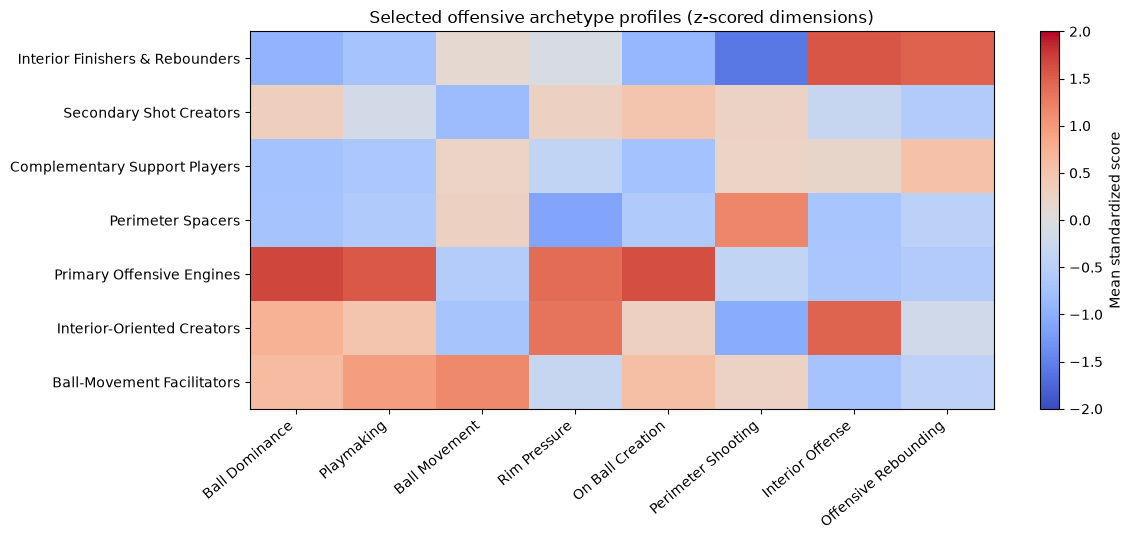

In [6]:
profiles = (
    analysis.groupby(["OFFENSIVE_CLUSTER", "OFFENSIVE_ARCHETYPE"])[OFFENSE_FEATURES]
    .mean().sort_index()
)
display(profiles.round(2))

fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.imshow(profiles.to_numpy(), aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
ax.set_yticks(np.arange(len(profiles)))
ax.set_yticklabels([name for _, name in profiles.index])
ax.set_xticks(np.arange(len(OFFENSE_FEATURES)))
ax.set_xticklabels([feature.replace("_SCORE", "").replace("_", " ").title() for feature in OFFENSE_FEATURES],
                   rotation=40, ha="right")
ax.set_title("Selected offensive archetype profiles (z-scored dimensions)")
fig.colorbar(image, ax=ax, label="Mean standardized score")
fig.tight_layout()
plt.show()

### Profiles in two dimensions (visualization only)

PCA projects our eight-dimensional space onto two axes so that we can inspect relative separation and overlap. KMeans was fitted on all eight original dimension scores, not on the two PCA coordinates. Overlapping points in this picture are not necessarily neighbors in the original space.

This visualization illustrates the fluid nature of nba playing styles, there aren't necessarily any clear cut groupings. Players typically have more of a unique identity so no clustering algorithm will ever create perfect archetypes of playing style.

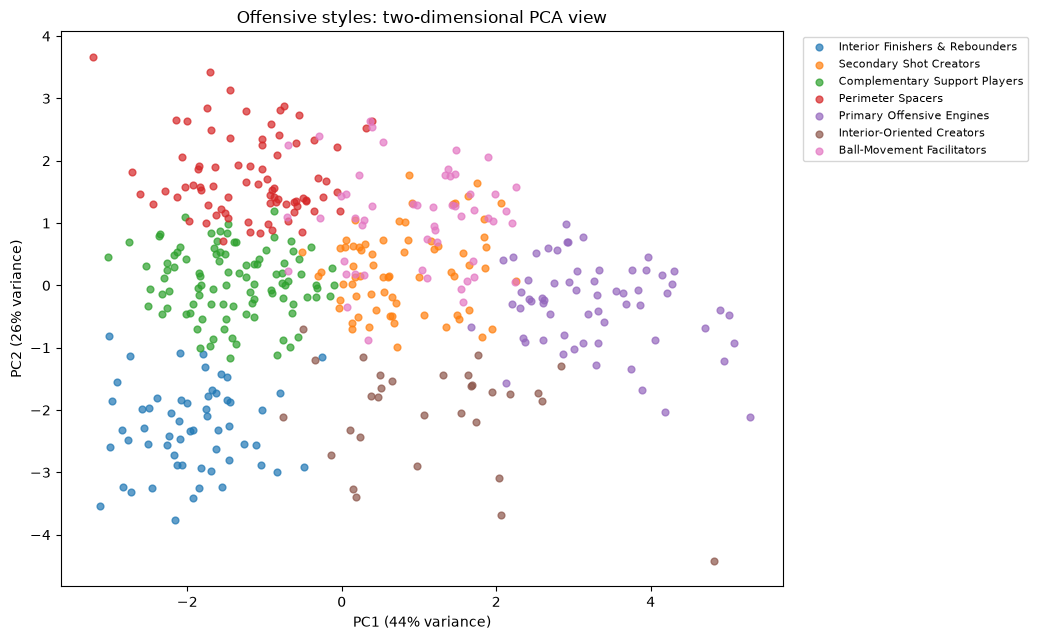

In [7]:
pca = PCA(n_components=2)
coords = pca.fit_transform(analysis[OFFENSE_FEATURES])

fig, ax = plt.subplots(figsize=(10.5, 6.5))
for cluster, archetype in sorted(OFFENSIVE_ARCHETYPE_NAMES.items()):
    mask = analysis["OFFENSIVE_CLUSTER"].to_numpy() == cluster
    ax.scatter(coords[mask, 0], coords[mask, 1], s=24, alpha=0.7,
               label=archetype)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
ax.set_title("Offensive styles: two-dimensional PCA view")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

### Interpreting the seven offensive groups

These descriptions were developed from the selected primary model and should be checked against the recomputed centroid table above whenever the feature data change.

| Archetype | Central stylistic signal | Important interpretation |
|---|---|---|
| **Interior Finishers & Rebounders** | Very high interior offensive activity and offensive rebounding; low perimeter shooting | Interior-oriented supporting roles; finisher describes role, not field-goal efficiency |
| **Secondary Shot Creators** | Above-average on-ball creation and rim pressure; below-average ball movement | Players who create some of their own offense without the extreme involvement of primary engines |
| **Complementary Support Players** | Lower ball dominance and on-ball creation, with varied secondary contributions | Broad support category; individual players within it may still have different specialties |
| **Perimeter Spacers** | High perimeter shooting involvement, low rim pressure and interior activity | Perimeter-oriented off-ball scoring roles, not necessarily the best 3-point shooters |
| **Primary Offensive Engines** | Very high ball dominance, playmaking, rim pressure, and on-ball creation | High-responsibility offensive initiators |
| **Interior-Oriented Creators** | High paint activity and rim pressure alongside some creation responsibility | A comparatively unstable style group with overlapping boundaries |
| **Ball-Movement Facilitators** | High touch-adjusted passing and playmaking | Passing-oriented creators distinct from the most ball-dominant initiators |

**Interpretive rule:** Labels summarize the group's dominant measured features. They should not be taken as claims about shooting accuracy, winning impact, or fixed positional assignments.

### 7. Representative players and archetype interpretation

A representative player is close to the cluster centroid in the eight-dimensional feature space. They are typical examples of the measured style, not necessarily the most talented or most famous members. A player can also have a clear main archetype while sharing traits with nearby groups.

The tables below show the seven closest players for each archetype. After inspecting these examples, the final archetype names can be documented alongside a short basketball interpretation.

In [8]:
centroid_distances = model.transform(analysis[OFFENSE_FEATURES].to_numpy())
assigned = analysis["OFFENSIVE_CLUSTER"].to_numpy(dtype=int)
analysis["DIST_TO_OWN_CENTER"] = centroid_distances[np.arange(len(analysis)), assigned]

# Higher margin: much closer to assigned center than the next-closest center.
ordered = np.sort(centroid_distances, axis=1)
analysis["CENTROID_MARGIN"] = ordered[:, 1] - ordered[:, 0]

representative_rows = []
for cluster, name in sorted(OFFENSIVE_ARCHETYPE_NAMES.items()):
    group = analysis.loc[analysis["OFFENSIVE_CLUSTER"] == cluster]
    top = group.nsmallest(7, "DIST_TO_OWN_CENTER")
    representative_rows.append(top)
    print(f"\n{cluster}: {name} ({len(group)} players)")
    display(top[["PLAYER_NAME", "DIST_TO_OWN_CENTER", "CENTROID_MARGIN"]].round(3))

representatives = pd.concat(representative_rows, ignore_index=True)


0: Interior Finishers & Rebounders (58 players)


,PLAYER_NAME,DIST_TO_OWN_CENTER,CENTROID_MARGIN
413,Tony Bradley,0.735,2.197
381,Ryan Kalkbrenner,0.804,2.184
140,Goga Bitadze,0.829,2.245
377,Rudy Gobert,0.855,1.917
73,Clint Capela,0.875,2.289
330,Neemias Queta,0.885,1.996
296,Luke Kornet,0.930,2.026



1: Secondary Shot Creators (69 players)


,PLAYER_NAME,DIST_TO_OWN_CENTER,CENTROID_MARGIN
421,Trey Murphy III,0.708,1.657
440,Will Riley,0.745,1.438
35,Bilal Coulibaly,0.800,1.170
334,Nickeil Alexander-Walker,0.805,1.564
365,Quentin Grimes,0.818,1.327
5,Aaron Wiggins,0.867,1.004
95,De'Andre Hunter,0.933,0.975



2: Complementary Support Players (98 players)


,PLAYER_NAME,DIST_TO_OWN_CENTER,CENTROID_MARGIN
270,Kobe Brown,0.550,1.403
161,Jabari Walker,0.805,1.437
104,Derrick Jones Jr.,0.823,0.895
185,Jamir Watkins,0.959,0.409
388,Santi Aldama,0.996,0.949
25,Asa Newell,1.006,1.234
311,Micah Peavy,1.043,0.939


... (4 outputs left out)


5: Interior-Oriented Creators (31 players)


,PLAYER_NAME,DIST_TO_OWN_CENTER,CENTROID_MARGIN
210,Jimmy Butler III,1.107,1.658
11,Alex Sarr,1.184,1.491
239,Julius Randle,1.312,0.972
132,Evan Mobley,1.402,1.479
353,Paolo Banchero,1.517,0.593
103,Derik Queen,1.536,1.484
354,Pascal Siakam,1.559,1.001



6: Ball-Movement Facilitators (53 players)


,PLAYER_NAME,DIST_TO_OWN_CENTER,CENTROID_MARGIN
174,Jalen Pickett,0.797,1.548
244,Kam Jones,0.859,1.703
224,Jordan McLaughlin,0.870,1.973
249,Keaton Wallace,0.883,2.008
40,Bones Hyland,0.937,1.482
228,Jose Alvarado,0.967,1.855
42,Brandin Podziemski,1.038,0.740


### 8. Offensive player similarity

Our primary similarity measure is the root mean squared difference across the eight standardized offensive dimensions:

$
d(a,b) = \sqrt{\frac{1}{8}\sum_{j=1}^{8}\left(z_{aj}-z_{bj}\right)^2}
$

- Smaller distance means a more similar offensive role profile.
- Every dimension contributes one equally weighted squared difference.
- Since the inputs are standardized, the comparison is about style responsibilities, not about raw career totals or overall player value.
- Similar players can be in different KMeans groups; a categorical boundary should not override a close continuous profile.

The source implementation is similar_players() and explain_similarity() in clustering_similarity.py.

In [9]:
# Use a representative Primary Offensive Engines player as a reproducible example.

anchor_cluster = next(
    cluster for cluster, name in OFFENSIVE_ARCHETYPE_NAMES.items()
    if name == "Primary Offensive Engines"
)
anchor = (
    analysis.loc[analysis["OFFENSIVE_CLUSTER"] == anchor_cluster]
    .nsmallest(1, "DIST_TO_OWN_CENTER").iloc[0]
)
anchor_id = int(anchor["PLAYER_ID"])

neighbors = similar_players(analysis, anchor_id, top_n=10)
print(f"Reference player: {anchor['PLAYER_NAME']} — {anchor['OFFENSIVE_ARCHETYPE']}")
display(neighbors.round(3))

Reference player: De'Aaron Fox — Primary Offensive Engines


,PLAYER_ID,PLAYER_NAME,OFFENSIVE_ARCHETYPE,OFFENSIVE_DISTANCE
0,1631157,Ryan Rollins,Primary Offensive Engines,0.275
1,1629636,Darius Garland,Primary Offensive Engines,0.310
2,1627750,Jamal Murray,Primary Offensive Engines,0.338
3,1630559,Austin Reaves,Primary Offensive Engines,0.387
4,1642450,Daniss Jenkins,Primary Offensive Engines,0.388
5,1630178,Tyrese Maxey,Primary Offensive Engines,0.403
6,1628369,Jayson Tatum,Primary Offensive Engines,0.452
7,1630175,Cole Anthony,Primary Offensive Engines,0.455
8,1627749,Dejounte Murray,Primary Offensive Engines,0.456
9,201950,Jrue Holiday,Primary Offensive Engines,0.470


### Explaining one player-to-player comparison

Squared differences can be attributed to individual dimensions. Their shares sum to 100% of squared distance for distinct profiles, helping us explain why two players are farther apart or close together. These are descriptive contributions, not feature importance from a predictive model.

De'Aaron Fox vs. Ryan Rollins: distance = 0.275


,DIMENSION,PLAYER_A,PLAYER_B,ABSOLUTE_DIFFERENCE,DISTANCE_CONTRIBUTION,DISTANCE_SHARE
0,OFFENSIVE_REBOUNDING_SCORE,-0.890,-0.412,0.478,0.029,0.378
1,PLAYMAKING_SCORE,1.728,1.407,0.321,0.013,0.171
2,BALL_MOVEMENT_SCORE,-0.523,-0.207,0.315,0.012,0.164
3,PERIMETER_SHOOTING_SCORE,-0.347,-0.042,0.306,0.012,0.155
4,BALL_DOMINANCE_SCORE,1.324,1.574,0.249,0.008,0.103
5,INTERIOR_OFFENSE_SCORE,-0.919,-1.015,0.096,0.001,0.015
6,RIM_PRESSURE_SCORE,1.120,1.033,0.087,0.001,0.013
7,ON_BALL_CREATION_SCORE,1.739,1.763,0.024,0.000,0.001


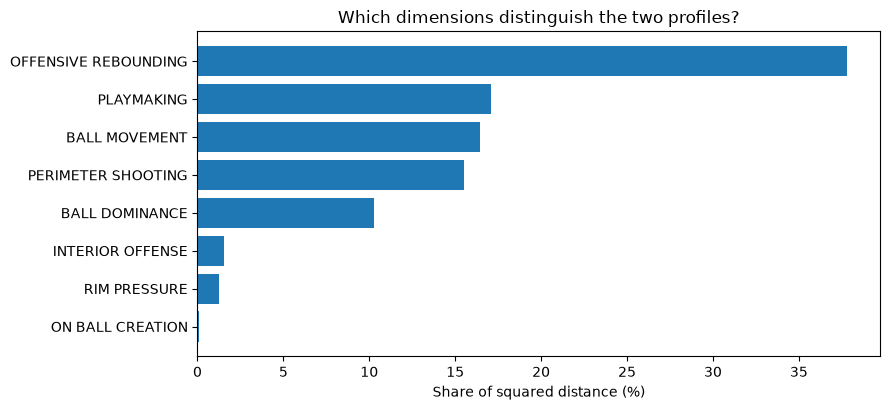

In [10]:
neighbor_id = int(neighbors.iloc[0]["PLAYER_ID"])
neighbor_name = neighbors.iloc[0]["PLAYER_NAME"]
distance, explanation = explain_similarity(analysis, anchor_id, neighbor_id)

print(f"{anchor['PLAYER_NAME']} vs. {neighbor_name}: distance = {distance:.3f}")
display(explanation.round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
plot_data = explanation.sort_values("DISTANCE_SHARE")
ax.barh(plot_data["DIMENSION"].str.replace("_SCORE", "", regex=False).str.replace("_", " ", regex=False),
        100 * plot_data["DISTANCE_SHARE"])
ax.set_xlabel("Share of squared distance (%)")
ax.set_title("Which dimensions distinguish the two profiles?")
fig.tight_layout()
plt.show()

### 9. Sensitivity to the choice of similarity metric
We compared normalized Euclidean distance with cosine distance on the same eight composite scores. Euclidean distance is the selected method because it preserves differences in the levels of standardized offensive responsibilities; cosine emphasizes profile direction instead.

The top-10 neighbor overlap offers a simple way to assess how sensitive recommended comparisons are to that choice. High overlap would mean the methods give broadly similar recommendations; lower overlap identifies profiles for which the method matters.

Earlier exploratory work also tested a family-balanced individual-feature cosine method and feature-family perturbations. Those experiments informed our choice, but are not reimplemented in this concise official notebook.

In [11]:
X_similarity = analysis[OFFENSE_FEATURES].to_numpy()
euclidean = euclidean_distances(X_similarity) / np.sqrt(len(OFFENSE_FEATURES))
cosine = cosine_distances(X_similarity)

np.fill_diagonal(euclidean, np.inf)
np.fill_diagonal(cosine, np.inf)

k_neighbors = 10
retention = []
for i in range(len(X_similarity)):
    e_neighbors = set(np.argsort(euclidean[i])[:k_neighbors])
    c_neighbors = set(np.argsort(cosine[i])[:k_neighbors])
    retention.append(len(e_neighbors & c_neighbors) / k_neighbors)

analysis["EUCLIDEAN_COSINE_TOP10_OVERLAP"] = retention
print("Mean top-10 overlap (Euclidean vs. cosine):", round(float(np.mean(retention)), 3))
print("Median overlap:", round(float(np.median(retention)), 3))

display(
    analysis.nsmallest(10, "EUCLIDEAN_COSINE_TOP10_OVERLAP")[[
        "PLAYER_NAME", "OFFENSIVE_ARCHETYPE", "EUCLIDEAN_COSINE_TOP10_OVERLAP"
    ]]
)

Mean top-10 overlap (Euclidean vs. cosine): 0.645
Median overlap: 0.7


,PLAYER_NAME,OFFENSIVE_ARCHETYPE,EUCLIDEAN_COSINE_TOP10_OVERLAP
166,Jahmai Mashack,Complementary Support Players,0.0
4,Aaron Nesmith,Complementary Support Players,0.1
20,Anthony Black,Secondary Shot Creators,0.1
42,Brandin Podziemski,Ball-Movement Facilitators,0.1
64,Caris LeVert,Ball-Movement Facilitators,0.1
165,Jae'Sean Tate,Complementary Support Players,0.1
225,Jordan Miller,Secondary Shot Creators,0.1
277,Kyle Filipowski,Complementary Support Players,0.1
279,Kyshawn George,Ball-Movement Facilitators,0.1
299,Malevy Leons,Interior Finishers & Rebounders,0.1


### 10. Conclusions, limitations, and next steps

#### Selected findings

- A seven-cluster KMeans solution provides interpretable, distinct offensive-role profiles, including specialized perimeter spacers and multiple creator types.
- A five-cluster solution is more compact but merges some responsibilities that are analytically useful to distinguish.
- Not all groups are equally stable: Interior-Oriented Creators is a comparatively fuzzy boundary. Treat the archetype as a broad description, not an immutable player identity.
- Normalized Euclidean similarity complements archetypes by preserving continuous stylistic proximity; players near a cluster boundary may have strong neighbors in another group.

#### Limitations

1. Style ≠ value. These metrics describe offensive roles, not individual scoring efficiency, team impact, or player quality.
2. Context matters. Coaching decisions, lineups, team schemes, injuries, and sample-size thresholds influence the observed profiles.
3. Feature construction matters. Residual adjustments, log transformations, correlated dimensions, and standardization affect distances and cluster assignments.
4. Labels depend on the fitted model. Preserve the fitted estimator, feature order, player assignments, and archetype mapping together; verify them if the data are refreshed.
5. Single-season evidence. Cross-season stability and out-of-sample relevance should be tested before claiming persistent NBA player types.
6. Internal validity is not external validation. Silhouette, ARI, and face-validity examples help characterize a partition but cannot establish that it is the uniquely correct taxonomy.

#### Next Steps

Next we will focus on our offensive and defensive valuation metrics. We will discuss why the defensive metrics available did not suffice for a clustering model similar to our offensive archetypes and why the outcome based nature of defensive statistics make defensive valuation the most logical step for a similarity based scouting tool.